In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
crime = pd.read_csv("crime_dataset_india.csv")

In [9]:
crime

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,Unnamed: 4,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed
0,1,2/1/2020 0:00,1/1/2020 0:00,1/1/2020 1:11,NaN,Ahmedabad,576,IDENTITY THEFT,16,M,Blunt Object,Violent Crime,13,No,NaN
1,2,1/1/2020 19:00,1/1/2020 1:00,1/1/2020 6:26,NaN,Chennai,128,HOMICIDE,37,M,Poison,Other Crime,9,No,NaN
2,3,2/1/2020 5:00,1/1/2020 2:00,1/1/2020 14:30,NaN,Ludhiana,271,KIDNAPPING,48,F,Blunt Object,Other Crime,15,No,NaN
3,4,1/1/2020 5:00,1/1/2020 3:00,1/1/2020 14:46,NaN,Pune,170,BURGLARY,49,F,Firearm,Other Crime,1,Yes,29-04-2020 05:00
4,5,1/1/2020 21:00,1/1/2020 4:00,1/1/2020 16:51,NaN,Pune,421,VANDALISM,30,F,Other,Other Crime,18,Yes,8/1/2020 21:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40155,40156,1/8/2024 16:00,7/31/2024 3:00,31-07-2024 05:05,NaN,Kolkata,312,COUNTERFEITING,78,F,Firearm,Other Crime,12,No,NaN
40156,40157,31-07-2024 14:00,7/31/2024 4:00,31-07-2024 04:14,NaN,Mumbai,300,ILLEGAL POSSESSION,75,F,NaN,Other Crime,2,Yes,29-09-2024 14:00
40157,40158,2/8/2024 3:00,7/31/2024 5:00,31-07-2024 21:33,NaN,Kanpur,423,VEHICLE - STOLEN,68,M,Other,Violent Crime,6,No,NaN
40158,40159,1/8/2024 19:00,7/31/2024 6:00,31-07-2024 11:05,NaN,Patna,311,SEXUAL ASSAULT,11,M,Blunt Object,Violent Crime,1,No,NaN


In [10]:
crime.columns

Index(['Report Number', 'Date Reported', 'Date of Occurrence',
       'Time of Occurrence', 'Unnamed: 4', 'City', 'Crime Code',
       'Crime Description', 'Victim Age', 'Victim Gender', 'Weapon Used',
       'Crime Domain', 'Police Deployed', 'Case Closed', 'Date Case Closed'],
      dtype='object')

added column of year


In [11]:
crime["Time of Occurrence"] = pd.to_datetime(
    crime["Time of Occurrence"],
    format='mixed',
    dayfirst=True,
    errors='coerce' # Coerce unparseable dates to NaT
)
crime["Year"] = crime["Time of Occurrence"].dt.year

In [12]:
crime.head()

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,Unnamed: 4,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed,Year
0,1,2/1/2020 0:00,1/1/2020 0:00,2020-01-01 01:11:00,NaN,Ahmedabad,576,IDENTITY THEFT,16,M,Blunt Object,Violent Crime,13,No,NaN,2020
1,2,1/1/2020 19:00,1/1/2020 1:00,2020-01-01 06:26:00,NaN,Chennai,128,HOMICIDE,37,M,Poison,Other Crime,9,No,NaN,2020
2,3,2/1/2020 5:00,1/1/2020 2:00,2020-01-01 14:30:00,NaN,Ludhiana,271,KIDNAPPING,48,F,Blunt Object,Other Crime,15,No,NaN,2020
3,4,1/1/2020 5:00,1/1/2020 3:00,2020-01-01 14:46:00,NaN,Pune,170,BURGLARY,49,F,Firearm,Other Crime,1,Yes,29-04-2020 05:00,2020
4,5,1/1/2020 21:00,1/1/2020 4:00,2020-01-01 16:51:00,NaN,Pune,421,VANDALISM,30,F,Other,Other Crime,18,Yes,8/1/2020 21:00,2020


In [13]:
crime.tail()

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,Unnamed: 4,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed,Year
40155,40156,1/8/2024 16:00,7/31/2024 3:00,2024-07-31 05:05:00,NaN,Kolkata,312,COUNTERFEITING,78,F,Firearm,Other Crime,12,No,NaN,2024
40156,40157,31-07-2024 14:00,7/31/2024 4:00,2024-07-31 04:14:00,NaN,Mumbai,300,ILLEGAL POSSESSION,75,F,NaN,Other Crime,2,Yes,29-09-2024 14:00,2024
40157,40158,2/8/2024 3:00,7/31/2024 5:00,2024-07-31 21:33:00,NaN,Kanpur,423,VEHICLE - STOLEN,68,M,Other,Violent Crime,6,No,NaN,2024
40158,40159,1/8/2024 19:00,7/31/2024 6:00,2024-07-31 11:05:00,NaN,Patna,311,SEXUAL ASSAULT,11,M,Blunt Object,Violent Crime,1,No,NaN,2024
40159,40160,31-07-2024 17:00,7/31/2024 7:00,2024-07-31 17:19:00,NaN,Delhi,193,DOMESTIC VIOLENCE,43,F,Poison,Violent Crime,7,Yes,28-09-2024 17:00,2024


In [14]:
crime.columns

Index(['Report Number', 'Date Reported', 'Date of Occurrence',
       'Time of Occurrence', 'Unnamed: 4', 'City', 'Crime Code',
       'Crime Description', 'Victim Age', 'Victim Gender', 'Weapon Used',
       'Crime Domain', 'Police Deployed', 'Case Closed', 'Date Case Closed',
       'Year'],
      dtype='object')

In [15]:
#total no. of crime cases?

print("Total no. of crime: " + str(len(crime)))

Total no. of crime: 40160


In [16]:
#Statistical summary
crime.describe()


,Report Number,Time of Occurrence,Unnamed: 4,Crime Code,Victim Age,Police Deployed,Year
count,40160.000000,40160,0.0,40160.000000,40160.00000,40160.000000,40160.000000
mean,20080.500000,2022-04-17 03:26:55.228087808,NaN,349.360259,44.49126,10.006250,2021.817555
min,1.000000,2020-01-01 01:11:00,NaN,100.000000,10.00000,1.000000,2020.000000
25%,10040.750000,2021-02-22 20:22:15,NaN,225.000000,27.00000,5.000000,2021.000000
50%,20080.500000,2022-04-17 01:16:00,NaN,349.000000,44.00000,10.000000,2022.000000
75%,30120.250000,2023-06-09 10:10:15,NaN,474.000000,62.00000,15.000000,2023.000000
max,40160.000000,2024-07-31 21:42:00,NaN,599.000000,79.00000,19.000000,2024.000000
std,11593.337742,NaN,NaN,144.169205,20.22555,5.467951,1.336061


In [17]:
crime.shape[0]

40160

In [18]:
#Check missing value
crime.isnull().sum()

,0
Report Number,0
Date Reported,0
Date of Occurrence,0
Time of Occurrence,0
Unnamed: 4,40160
City,0
Crime Code,0
Crime Description,0
Victim Age,0
Victim Gender,0


In [19]:
#Which city have highest total crimes?

City_total = crime.groupby("City").size().sort_values(ascending=False)
City_total.head(10)

,0
City,
Delhi,5400
Mumbai,4415
Bangalore,3588
Hyderabad,2881
Kolkata,2518
Chennai,2493
Pune,2212
Ahmedabad,1817
Jaipur,1479


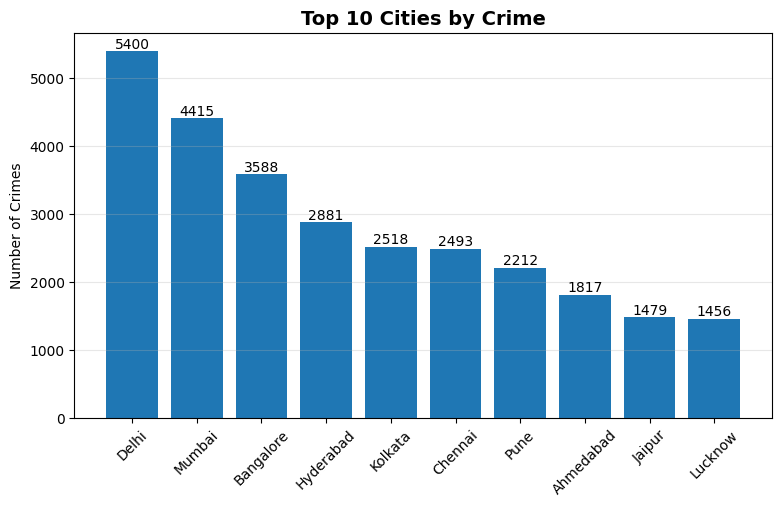

In [20]:
city_total = crime["City"].value_counts().head(10)

plt.figure(figsize=(9,5))

bars = plt.bar(city_total.index,
               city_total.values)

# Add values on top
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height,
             int(height),
             ha='center',
             va='bottom')

plt.title("Top 10 Cities by Crime", fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.ylabel("Number of Crimes")
plt.grid(axis='y', alpha=0.3)

plt.show()

In [21]:
#Percentage contribution of each state to national crime
(City_total / City_total.sum()) * 100

,0
City,
Delhi,13.446215
Mumbai,10.993526
Bangalore,8.934263
Hyderabad,7.173805
Kolkata,6.269920
Chennai,6.207669
Pune,5.507968
Ahmedabad,4.524402
Jaipur,3.682769


In [22]:
#whixh City has lowest crime
city_counts = crime['City'].value_counts()
lowest_city = city_counts.idxmin()
print("Lowest Crime City:", lowest_city)

Lowest Crime City: Rajkot


In [23]:
#What is the crime trend year by year?

year_counts = crime.groupby('Year').size()
year_counts

,0
Year,
2020,8769
2021,8761
2022,8765
2023,8758
2024,5107


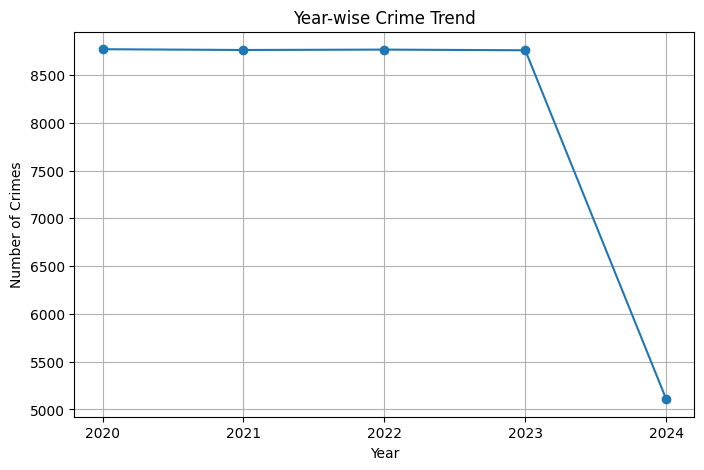

In [24]:
year_trend = crime.groupby("Year").size().sort_index()

plt.figure(figsize=(8,5))
plt.plot(year_trend.index, year_trend.values, marker="o")
plt.title("Year-wise Crime Trend")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")
plt.xticks(year_trend.index)
plt.grid(True)
plt.show()

In [25]:
#Which age group is most affected?
bins = [0,18,30,45,60,100]
labels = ['0-18','19-30','31-45','46-60','60+']

crime['Age Group'] = pd.cut(crime['Victim Age'], bins=bins, labels=labels)

age_group_counts = crime['Age Group'].value_counts()
print(age_group_counts)

Age Group
60+      10924
31-45     8667
46-60     8487
19-30     6961
0-18      5121
Name: count, dtype: int64


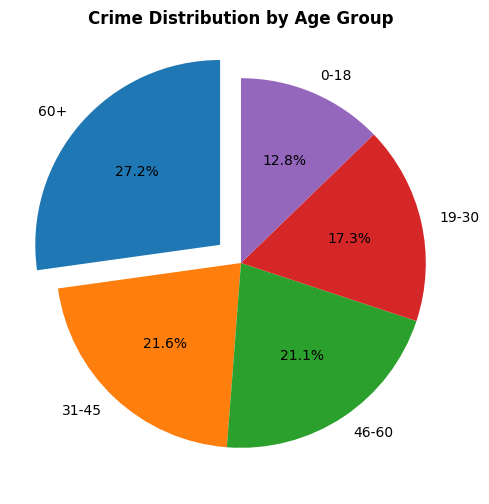

In [26]:
age_dist = crime["Age Group"].value_counts()

explode = [0.15 if i == age_dist.max() else 0 for i in age_dist.values]

plt.figure(figsize=(6,6))

plt.pie(age_dist.values,
        labels=age_dist.index,
        autopct="%1.1f%%",
        explode=explode,
        startangle=90)

plt.title("Crime Distribution by Age Group", fontweight='bold')
plt.show()

In [27]:
#Which gender is more vulnerable in each crime domain?
gender_counts = crime.groupby(['Victim Gender', 'Crime Domain']).size()
print(gender_counts)

Victim Gender  Crime Domain    
F              Fire Accident        2122
               Other Crime         12771
               Traffic Fatality     1074
               Violent Crime        6456
M              Fire Accident        1288
               Other Crime          7786
               Traffic Fatality      631
               Violent Crime        3700
X              Fire Accident         415
               Other Crime          2391
               Traffic Fatality      210
               Violent Crime        1316
dtype: int64


In [28]:
#What are the top 3 crimes in each city?
top_crimes = crime.groupby(['City','Crime Description']).size()\
               .groupby(level=0) \
               .nlargest(3)

print(top_crimes)

City           City           Crime Description  
Agra           Agra           ASSAULT                 47
                              ARSON                   43
                              PUBLIC INTOXICATION     43
Ahmedabad      Ahmedabad      ASSAULT                104
                              DOMESTIC VIOLENCE      102
                                                    ... 
Vasai          Vasai          EXTORTION               22
                              DRUG OFFENSE            21
Visakhapatnam  Visakhapatnam  TRAFFIC VIOLATION       45
                              FRAUD                   44
                              DRUG OFFENSE            42
Length: 87, dtype: int64


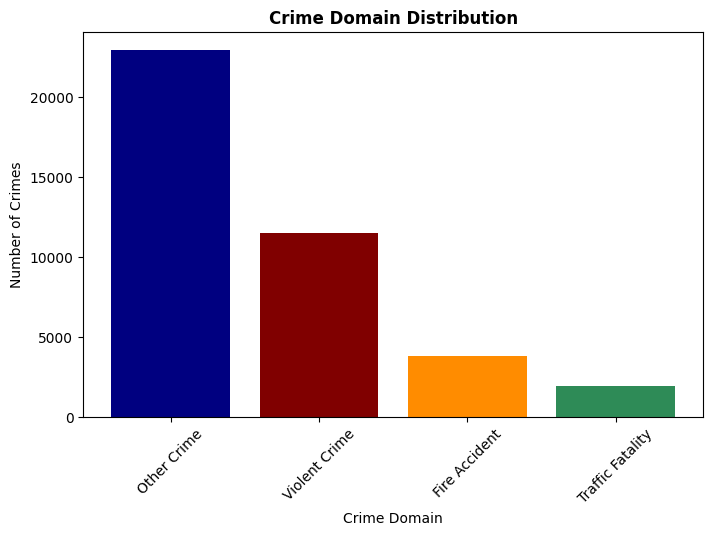

In [29]:
domain_dist = crime["Crime Domain"].value_counts()

colors = ["navy", "maroon", "darkorange", "seagreen"]

plt.figure(figsize=(8,5))

bars = plt.bar(domain_dist.index,
               domain_dist.values,
               color=colors)

plt.title("Crime Domain Distribution", fontweight="bold")
plt.xlabel("Crime Domain")
plt.ylabel("Number of Crimes")
plt.xticks(rotation=45)
plt.show()

In [30]:
#weapon is most used in violent crimes

violent = crime[crime['Crime Domain']=='Violent Crime']
weapon_counts = violent['Weapon Used'].value_counts()

print("Most Used Weapon:", weapon_counts.idxmax())

Most Used Weapon: Firearm


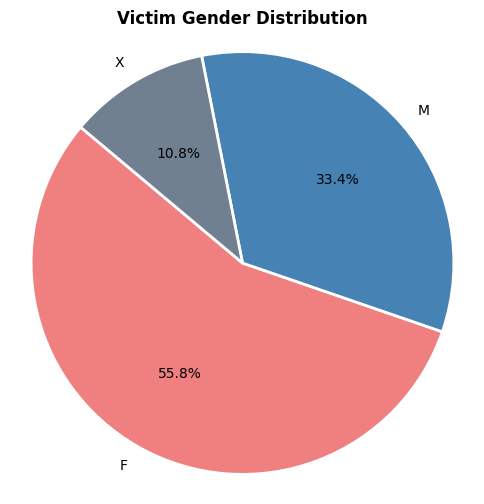

In [31]:
#Victim Gender
gender_dist = crime["Victim Gender"].value_counts()

colors = [ "lightcoral","steelblue", "slategray"]

plt.figure(figsize=(6,6))

plt.pie(gender_dist.values,
        labels=gender_dist.index,
        autopct="%1.1f%%",
        colors=colors,
        startangle=140,
        wedgeprops={"edgecolor":"white", "linewidth":2})

plt.title("Victim Gender Distribution", fontweight="bold")
plt.axis("equal")
plt.show()

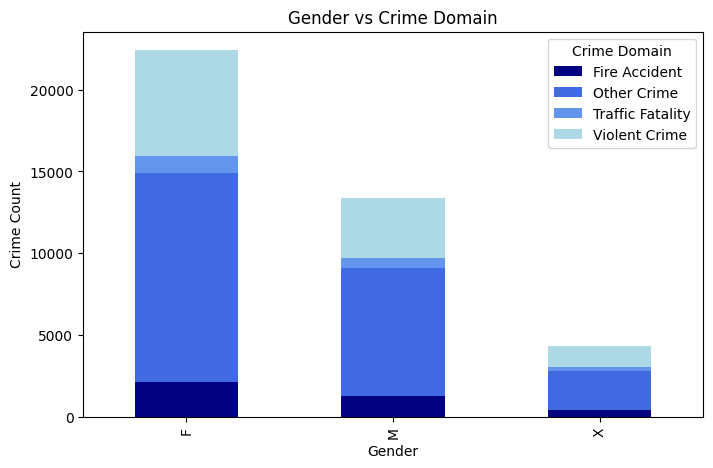

In [32]:
#Gender Vs. Crime domain
gender_domain = pd.crosstab(crime["Victim Gender"], crime["Crime Domain"])
colors = ["navy", "royalblue", "cornflowerblue", "lightblue"]
gender_domain.plot(kind="bar",
                   stacked=True,
                   figsize=(8,5),
                   color=colors)
plt.title("Gender vs Crime Domain")
plt.xlabel("Gender")
plt.ylabel("Crime Count")
plt.show()

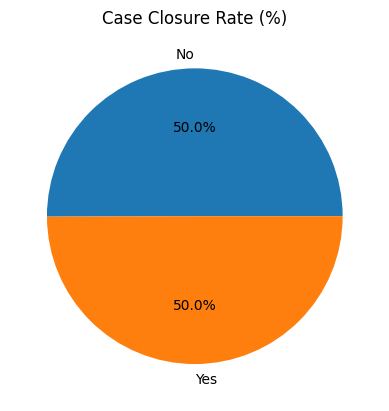

Case Closed
No     50.044821
Yes    49.955179
Name: proportion, dtype: float64


In [33]:
#case closure

closure_rate = crime["Case Closed"].value_counts(normalize=True) * 100

closure_rate.plot(kind="pie", autopct="%1.1f%%")
plt.title("Case Closure Rate (%)")
plt.ylabel("")
plt.show()

print(closure_rate)